# Figures

Save as PNG asks Python for the file. A chart is drawn by matplotlib on a white page, 2100 by 1400 pixels at 300 dpi; a picture is enlarged by a whole number with Pillow. This notebook makes both files, shows them here at a smaller size, and checks their size. It also shows how a line colour that is too pale for white is darkened.

In [1]:
# Standard library
import io
import math

In [2]:
# Third-party libraries
from IPython import display as ipython_display
from PIL import Image as PilImage

In [3]:
# Local libraries
from element_51 import Image
from element_51.figures import (
    GRAPHIC_RATIO,
    PAPER_HEIGHT,
    PAPER_WIDTH,
    Line,
    chart_png,
    contrast_with_white,
    darken_to,
    picture_png,
)

In [4]:
STEPS = 120
SIDE = 28
SHOWN_WIDTH = 600
WIGGLE = 0.02
FALL = 25.0
RISE = 30.0
BRIGHTEST = 255


def show(data: bytes) -> PilImage.Image:
    """Show a PNG file inline at a smaller size.

    Returns
    -------
    PilImage.Image
        The file as read, at its full size.
    """
    picture = PilImage.open(io.BytesIO(data))
    picture.load()
    small = picture.copy()
    small.thumbnail((SHOWN_WIDTH, SHOWN_WIDTH))
    buffer = io.BytesIO()
    small.save(buffer, format="PNG")
    ipython_display.display(ipython_display.Image(data=buffer.getvalue()))
    return picture

## A chart

Two lines, the way the editor sends them: a name, the numbers (`None` is a gap), the colour the card draws, and whether the user picked it. The orange is the theme's, so it is darkened; the green was picked, so it is used exactly.

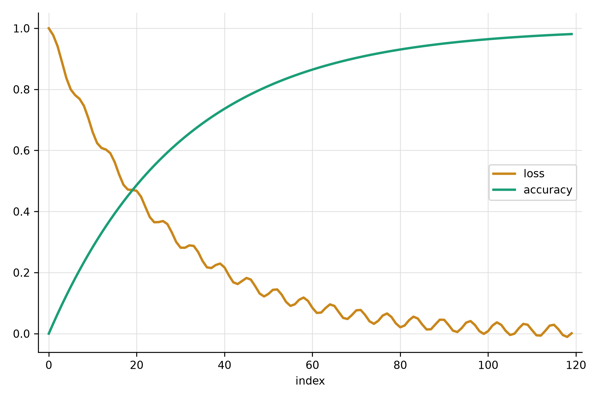

(2100, 1400) (299.9994, 299.9994)


In [5]:
loss = tuple(
    math.exp(-step / FALL) + WIGGLE * math.sin(step) for step in range(STEPS)
)
accuracy = tuple(1 - math.exp(-step / RISE) for step in range(STEPS))
lines = (
    Line(name="loss", values=loss, colour="#edc27b", chosen=False),
    Line(name="accuracy", values=accuracy, colour="#1b9e77", chosen=True),
)
figure = show(chart_png(lines))
print(figure.size, figure.info["dpi"])
assert figure.size == (PAPER_WIDTH, PAPER_HEIGHT)

## Pale colours on white

A graphic needs 3 to 1 against its background. The editor's own line colours are pale, made for a dark card, so the figure darkens each one, keeping its hue, only as far as it needs.

In [6]:
theme_colours = {
    "orange": "#edc27b",
    "green": "#94a95f",
    "blue": "#6fa8dc",
    "teal": "#5fc9c0",
}
for name, colour in theme_colours.items():
    darker = darken_to(colour)
    print(
        f"{name:7} {colour} {contrast_with_white(colour):.1f} to 1  ->  "
        f"{darker} {contrast_with_white(darker):.1f} to 1"
    )
    assert contrast_with_white(darken_to(colour)) >= GRAPHIC_RATIO

orange  #edc27b 1.7 to 1  ->  #c9871b 3.0 to 1
green   #94a95f 2.6 to 1  ->  #889d54 3.0 to 1
blue    #6fa8dc 2.5 to 1  ->  #579ad6 3.0 to 1
teal    #5fc9c0 2.0 to 1  ->  #38a49b 3.0 to 1


## A picture

A 28 by 28 grey ramp is enlarged 50 times, with crisp pixels, to 1400 by 1400.

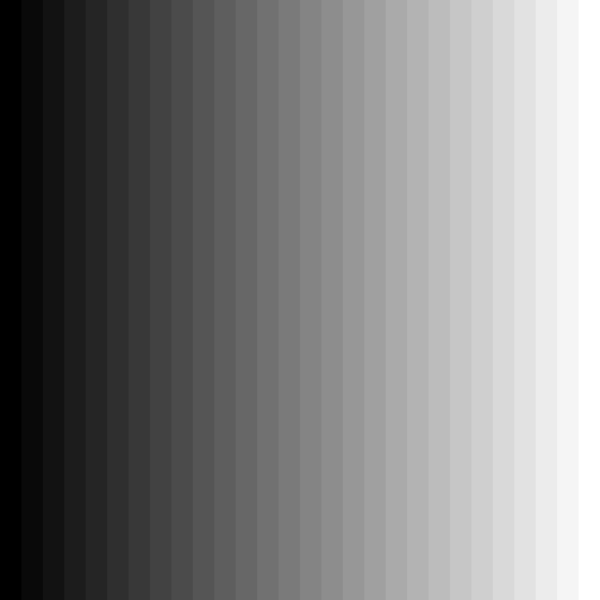

(1400, 1400)


In [7]:
row = bytes(column * BRIGHTEST // (SIDE - 1) for column in range(SIDE))
ramp = Image(width=SIDE, height=SIDE, channels=1, pixels=row * SIDE)
picture = show(picture_png(ramp))
print(picture.size)
assert picture.size == (SIDE * 50, SIDE * 50)

## A chart with no numbers

There is nothing to draw, and Python says so.

In [8]:
empty = (Line(name="loss", values=(None, None), colour="#1b9e77", chosen=True),)
reason = ""
try:
    chart_png(empty)
except ValueError as error:
    reason = str(error)
print(reason)
assert reason

the chart has no numbers to draw
